# 01 - EDA: DataCo (order-level)
Goal: understand lateness before modeling. Write 4-5 findings at the bottom.

In [1]:
import sys; sys.path.append("..")          # so `src` can be imported from notebooks/
import yaml, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from src.data.load import load_dataco
from src.data.clean import clean_dataco

cfg = yaml.safe_load(open("../config.yaml"))
raw = load_dataco("../" + cfg["paths"]["dataco"])
df = clean_dataco(raw)
print(raw.shape, "->", df.shape)
df.head()

(180519, 53) -> (180519, 43)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Profit Per Order,Order Region,Order State,Order Status,Product Card Id,Product Category Id,Product Name,Product Price,shipping date (DateOrders),Shipping Mode
0,CASH,2,4,88.790001,239.979996,Advance shipping,0,43,Camping & Hiking,Hickory,...,88.790001,Central America,Distrito Federal,CLOSED,957,43,Diamondback Women's Serene Classic Comfort Bi,299.980011,2015-01-03 00:00:00,Standard Class
1,PAYMENT,3,4,91.180000,193.990005,Advance shipping,0,48,Water Sports,Chicago,...,91.180000,South America,Risaralda,PENDING_PAYMENT,1073,48,Pelican Sunstream 100 Kayak,199.990005,2015-01-04 00:21:00,Standard Class
2,PAYMENT,3,4,68.250000,227.500000,Advance shipping,0,24,Women's Apparel,Chicago,...,68.250000,South America,Risaralda,PENDING_PAYMENT,502,24,Nike Men's Dri-FIT Victory Golf Polo,50.000000,2015-01-04 00:21:00,Standard Class
3,PAYMENT,3,4,36.470001,107.889999,Advance shipping,0,18,Men's Footwear,Chicago,...,36.470001,South America,Risaralda,PENDING_PAYMENT,403,18,Nike Men's CJ Elite 2 TD Football Cleat,129.990005,2015-01-04 00:21:00,Standard Class
4,CASH,5,4,33.590000,159.940002,Late delivery,1,46,Indoor/Outdoor Games,San Antonio,...,33.590000,South America,Risaralda,CLOSED,1014,46,O'Brien Men's Neoprene Life Vest,49.980000,2015-01-06 01:03:00,Standard Class


## 1. Data audit

In [2]:
print("Date range:", df["order date (DateOrders)"].min(), "->", df["order date (DateOrders)"].max())
print("Duplicates in raw:", raw.duplicated().sum())
miss = df.isna().mean().sort_values(ascending=False)
miss[miss > 0]

Date range: 2015-01-01 00:00:00 -> 2018-01-31 23:38:00
Duplicates in raw: 0


Series([], dtype: float64)

In [3]:
df["Late_delivery_risk"].value_counts(normalize=True).rename("share")

Late_delivery_risk
1    0.548291
0    0.451709
Name: share, dtype: float64

## 2. Late rate by shipping mode
Note: DataCo is known to show First Class as the *least* reliable. Report it honestly as a dataset artifact.

,late_rate,orders,scheduled_days,real_days
Shipping Mode,,,,
Standard Class,0.381,107752,4.0,3.996
Same Day,0.457,9737,0.0,0.478
Second Class,0.766,35216,2.0,3.991
First Class,0.953,27814,1.0,2.000


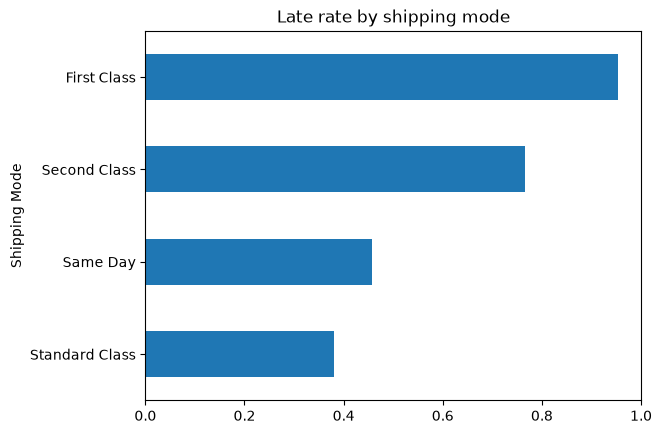

In [4]:
by_mode = df.groupby("Shipping Mode").agg(
    late_rate=("Late_delivery_risk", "mean"),
    orders=("Late_delivery_risk", "size"),
    scheduled_days=("Days for shipment (scheduled)", "mean"),
    real_days=("Days for shipping (real)", "mean"),
).round(3).sort_values("late_rate")
display(by_mode)
by_mode["late_rate"].plot.barh(title="Late rate by shipping mode"); plt.show()

## 3. Late rate by market, region and department

In [5]:
for col in ["Market", "Order Region", "Department Name", "Type", "Customer Segment"]:
    t = df.groupby(col)["Late_delivery_risk"].agg(["mean", "size"]).round(3).sort_values("mean")
    print(f"\n--- {col} ---"); display(t)


--- Market ---


,mean,size
Market,,
LATAM,0.544,51594
Africa,0.546,11614
USCA,0.548,25799
Pacific Asia,0.550,41260
Europe,0.552,50252



--- Order Region ---


,mean,size
Order Region,,
Canada,0.488,959
West Africa,0.528,3696
Caribbean,0.531,8318
Southern Africa,0.533,1157
Northern Europe,0.540,9792
West of USA,0.540,7993
Oceania,0.540,10148
Eastern Asia,0.543,7280
South America,0.543,14935



--- Department Name ---


,mean,size
Department Name,,
Discs Shop,0.544,2026
Apparel,0.547,48998
Footwear,0.547,14525
Fan Shop,0.548,66861
Golf,0.548,33220
Technology,0.550,1465
Outdoors,0.555,9686
Fitness,0.555,2479
Health and Beauty,0.558,362



--- Type ---


,mean,size
Type,,
TRANSFER,0.485,49883
CASH,0.566,19616
DEBIT,0.572,69295
PAYMENT,0.575,41725



--- Customer Segment ---


,mean,size
Customer Segment,,
Corporate,0.547,54789
Consumer,0.548,93504
Home Office,0.551,32226


## 4. Scheduled vs real shipping days

In [6]:
pd.crosstab(df["Days for shipment (scheduled)"], df["Days for shipping (real)"])

Days for shipping (real),0,1,2,3,4,5,6
Days for shipment (scheduled),,,,,,,
0,5080,4657,0,0,0,0,0
1,0,0,27814,0,0,0,0
2,0,0,7138,7065,6978,7052,6983
4,0,0,21666,21700,21535,21111,21740


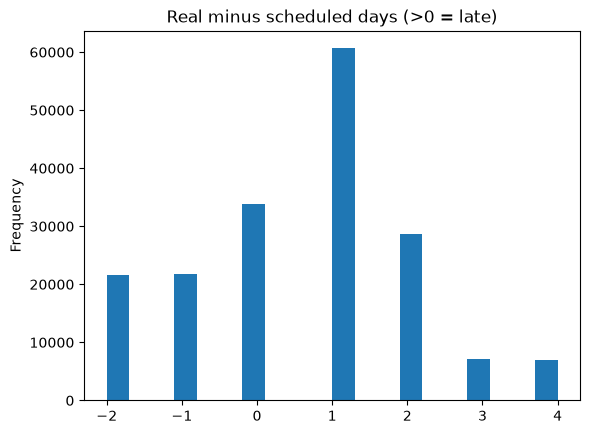

Share with gap > 0: 0.573 | late label rate: 0.548


In [7]:
df["gap_days"] = df["Days for shipping (real)"] - df["Days for shipment (scheduled)"]
df["gap_days"].plot.hist(bins=20, title="Real minus scheduled days (>0 = late)"); plt.show()
print("Share with gap > 0:", (df["gap_days"] > 0).mean().round(3),
      "| late label rate:", df["Late_delivery_risk"].mean().round(3))

## 5. Late rate over time and vs profit

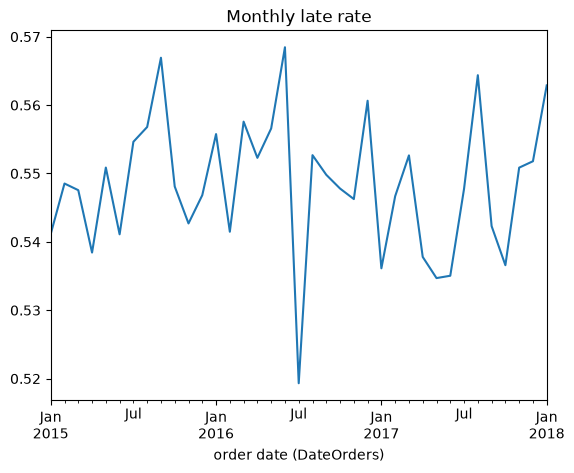

,Order Profit Per Order,Sales,Order Item Discount Rate
Late_delivery_risk,,,
0,22.40,204.29,0.1
1,21.62,203.34,0.1


In [8]:
m = df.set_index("order date (DateOrders)")["Late_delivery_risk"].resample("ME").mean()
m.plot(title="Monthly late rate"); plt.show()
df.groupby("Late_delivery_risk")[["Order Profit Per Order", "Sales", "Order Item Discount Rate"]].mean().round(2)

In [9]:
import pandas as pd
r = pd.read_csv("../" + cfg["paths"]["dataco"], encoding="latin-1")
d = pd.to_datetime(r["order date (DateOrders)"], errors="coerce")
print("rows in file:", len(r), "| unparseable dates:", d.isna().sum())
print(r.loc[d.isna(), "order date (DateOrders)"].head(10).tolist())
print(r["order date (DateOrders)"].head(5).tolist())

rows in file: 180519 | unparseable dates: 71103
['01-12-2018 23:51', '01-12-2018 23:30', '01-12-2018 23:09', '01-12-2018 22:48', '01-12-2018 22:27', '01-12-2018 22:05', '01-12-2018 21:44', '01-12-2018 21:23', '01-12-2018 21:02', '01-12-2018 20:41']
['1/31/2018 22:56', '1/13/2018 12:27', '1/13/2018 12:06', '1/13/2018 11:45', '1/13/2018 11:24']


## Findings (fill in)
1. Shipping mode almost fully determines lateness, and scheduled days are fixed per mode (0, 1, 2 and 4). First Class always takes 2 days against 1 scheduled, so it is late by construction. This is a dataset artifact.

2. Real days within a mode are spread almost evenly (about 21,000 to 21,700 orders for each value under Standard). Lateness within a mode is essentially random.

3. Market, region, department and segment barely matter, with late rates of 54% to 56%. The extremes shrank on the full data (Central Africa went from 63% to 58%), so they were sampling noise.

4. TRANSFER payments are late 48.5% of the time, against 56.6% to 57.5% for the others. Check whether this is just a different shipping-mode mix with pd.crosstab(df["Type"], df["Shipping Mode"], normalize="index").

5. Profit and sales hardly differ between late and on-time orders (22.40 vs. 21.62 profit).

6. The label isn’t exactly “real days greater than scheduled days”: 57.3% have a positive gap but 54.8% are labeled late. My guess is cancelled orders, which you can check with pd.crosstab(df["Delivery Status"], df["Late_delivery_risk"]).

7. Data quality: the raw file had Excel date corruption that affected 39% of rows. You detected and repaired it.

## Leakage columns to exclude later
`Days for shipping (real)`, `Delivery Status`, `Order Status`, `shipping date (DateOrders)`